# ЛР10. Сравнительное исследование моделей text-to-image

**Вариант 7:** бриф c = ⌈7/6⌉ = 2 — обложка подкаста о городе; пара k = ((7 − 1) mod 6) + 1 = 1 — SD Turbo (модель A) и LCM Dreamshaper v7 (модель B); seed 101…105.

Бриф: `square podcast cover about the city environment, abstract layered skyline of geometric shapes, teal and orange palette, minimal flat style, no text, no people`

| Модель | Ревизия | Конфигурация (таблица 2.2, не меняется) |
| --- | --- | --- |
| A — `stabilityai/sd-turbo` | `b261bac6…` | 1 шаг, guidance 0,0, 512×512 |
| B — `SimianLuo/LCM_Dreamshaper_v7` | `a85df6a8…` | 4 шага, guidance 8,0, 512×512 |

## Гипотезы и допуск — зафиксированы до запуска (12.11.2026 11:24 МСК)

- **H1** (гипотеза варианта): LCM ближе к брифу, чем SD Turbo: `clip_brief` B выше A больше чем на 2s и больше допуска 1,0.
- **H2**: LCM медленнее SD Turbo примерно вдвое: отношение времени B/A не меньше 1,5.
- **H3**: `clip_text` различается не больше допуска 1,0 — текст в брифе запрещён.
- **H4**: `edge` и `contrast` различаются не больше чем на 10 % от A.
- **H5**: в слепой оценке LCM выбран не менее чем в 3 парах из 5.
- **H6**: слои горизонта читаются как отдельные бирюзовые и оранжевые геометрические полосы у каждой модели не менее чем на 3 seed из 5.

**Допуск практической пользы:** `clip_brief`, `clip_text` — 1,0 пункта; `edge`, `contrast` — 10 % от A; время — отношение 1,5. Значимость — признак |Δ| > 2s, s по модели A.

**Порядок:** сначала все расчёты (вариант 7, намеренная ошибка 2, демо-вариант), затем слепая оценка по листам без подписей и только после неё — ключ и листы с подписями моделей. Ячейка ключа останавливает «Выполнить всё», пока выбор не записан.

In [1]:
# Подготовка среды (раздел 4 методички). PyTorch образа Colab не трогаем; diffusers и transformers — версии, на которых проверена библиотека.
# torchao из образа Colab библиотекой не используется и ломает импорт diffusers (ЛР06, ЛР09), поэтому удаляется до импорта.
import sys
assert not {"diffusers", "transformers"} & set(sys.modules), "diffusers/transformers уже импортированы: перезапустите сеанс и выполните ячейки сверху"
%pip uninstall -y -q torchao
%pip install -q "diffusers==0.32.2" "transformers<5"

import importlib.metadata as md, importlib.util
assert importlib.util.find_spec("torchao") is None, "torchao не удалён: перезапустите сеанс и выполните ячейку снова"
assert md.version("diffusers") == "0.32.2", md.version("diffusers")
assert md.version("transformers").startswith("4.57."), md.version("transformers")
ENVIRONMENT_FIXES = ["torchao uninstalled before importing diffusers: not used by the library, breaks diffusers import in the Colab image",
                     'pip install "diffusers==0.32.2" "transformers<5" (section 4 of the manual)']
print("diffusers", md.version("diffusers"), "| transformers", md.version("transformers"), "| huggingface_hub", md.version("huggingface_hub"))

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.32.2 | transformers 4.57.6 | huggingface_hub 0.36.2


In [2]:
%%writefile lab10_lib.py
# ЛР 10. Сравнительное исследование моделей text-to-image. Библиотека учебных функций.
# Среда получения результатов (20.09.2026): Engee 26.8.2-H3 на процессоре; Python 3.11; torch 2.4.1+cu121; diffusers 0.32.2; transformers 4.57.6.
# Установка пакетов, один раз (как в ЛР 9):  pip install "diffusers==0.32.2" "transformers<5"
import gc, os, time
import numpy as np
import torch
from scipy import ndimage
from diffusers import DiffusionPipeline, DPMSolverMultistepScheduler
from transformers import CLIPModel, CLIPProcessor

torch.set_num_threads(min(4, torch.get_num_threads()))
SEEDS = range(101, 106)
CLIP_ID = "openai/clip-vit-large-patch14"
CLIP_REVISION = "32bd64288804d66eefd0ccbe215aa642df71cc41"
TEXT_PROBE = "written text and letters"

# Конфигурация модели = веса + планировщик + число шагов + масштаб управления + размер кадра. Всё это входит в «модель» при сравнении.
MODELS = {
    "turbo": dict(repo="stabilityai/sd-turbo", revision="b261bac6fd2cf515557d5d0707481eafa0485ec2", steps=1, guidance=0.0, size=512,
                  note="дистиллированная SD 2.1, 1 шаг, без управления"),
    "lcm": dict(repo="SimianLuo/LCM_Dreamshaper_v7", revision="a85df6a8bd976cdd08b4fd8f3b73f229c9e54df5", steps=4, guidance=8.0, size=512,
                note="латентная согласованность, 4 шага"),
    "bk": dict(repo="nota-ai/bk-sdm-tiny", revision="0364108e53b7f7f4d2585e817a0b7a83dc261cfa", steps=10, guidance=7.5, size=512,
               scheduler="dpm", note="облегчённая SD 1.x, DPM-Solver++, 10 шагов"),
    "amused": dict(repo="amused/amused-256", revision="09b6259bf96dbe6d70a852b70812420fe02df55e", steps=12, guidance=10.0, size=256,
                   note="маскированные токены (не диффузия), 256×256, 12 шагов"),
}
# Пять брифов (английские, как в ЛР 5): одинаковый запрос для всех моделей
BRIEFS = [
    "editorial poster concept for a robotics festival, glowing mechanical arm silhouette, deep blue and amber palette, clean composition, no text, no logo, no people",
    "square podcast cover about the city environment, abstract layered skyline of geometric shapes, teal and orange palette, minimal flat style, no text, no people",
    "poster concept for a science exhibition, abstract constellation of connected nodes, dark background with white and cyan lines, balanced composition, no text, no logo",
    "visual for an ecology lecture series, stylized forest canopy seen from above, layered green shapes, soft morning light, no text, no people",
    "cover art for an electronic music release, brushed metal surface with iridescent reflections, macro photography style, strong contrast, no text, no logo, no people",
]
# Шесть сравнений: пары четырёх моделей (фактор варианта)
PAIRS = [("turbo", "lcm"), ("turbo", "bk"), ("turbo", "amused"), ("lcm", "bk"), ("lcm", "amused"), ("bk", "amused")]
METRICS = ("clip_brief", "clip_text", "edge", "contrast", "seconds")


def load_model(key):
    c = MODELS[key]
    pipe = DiffusionPipeline.from_pretrained(c["repo"], revision=c["revision"], torch_dtype=torch.float32, safety_checker=None,
                                             requires_safety_checker=False, use_safetensors=True)
    if c.get("scheduler") == "dpm":
        pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)
    pipe.set_progress_bar_config(disable=True)
    return pipe


def load_clip():
    model = CLIPModel.from_pretrained(CLIP_ID, revision=CLIP_REVISION, use_safetensors=True).eval()
    return model, CLIPProcessor.from_pretrained(CLIP_ID, revision=CLIP_REVISION)


def generate(pipe, key, prompt, seed, cfg=None):
    """cfg — необязательные замены параметров конфигурации (например, dict(steps=1)); нужны только для учебных ошибок."""
    c = {**MODELS[key], **(cfg or {})}
    g = torch.Generator("cpu").manual_seed(seed)
    t0 = time.perf_counter()
    img = pipe(prompt, num_inference_steps=c["steps"], guidance_scale=c["guidance"], height=c["size"], width=c["size"], generator=g).images[0]
    return img, time.perf_counter() - t0


@torch.no_grad()
def clip_sims(clip, img, texts):
    """Косинусное сходство изображения с текстами в CLIP, умноженное на 100 (не CLIPScore)."""
    model, proc = clip
    inp = proc(text=list(texts), images=img, return_tensors="pt", padding=True, truncation=True)
    out = model(**inp)
    a = out.image_embeds / out.image_embeds.norm(dim=-1, keepdim=True)
    b = out.text_embeds / out.text_embeds.norm(dim=-1, keepdim=True)
    return [float(v) * 100 for v in (a @ b.T)[0]]


def luma256(img):
    """Яркость изображения, приведённого к 256×256 (чтобы размер кадра не влиял на энергию границ)."""
    x = np.asarray(img.convert("RGB").resize((256, 256)), dtype=np.float64) / 255
    return 0.299 * x[..., 0] + 0.587 * x[..., 1] + 0.114 * x[..., 2]


def edge_energy(img):
    y = luma256(img)
    return float(np.mean(np.hypot(ndimage.sobel(y, axis=0), ndimage.sobel(y, axis=1)) / 8))


def contrast(img):
    return float(np.std(luma256(img)))


def measure(pipe, clip, key, ctx, seed, cfg=None):
    """Одно изображение: метрики и время генерации, с (без загрузки модели)."""
    img, dt = generate(pipe, key, BRIEFS[ctx], seed, cfg)
    s = clip_sims(clip, img, [BRIEFS[ctx], TEXT_PROBE])
    return dict(clip_brief=s[0], clip_text=s[1], edge=edge_energy(img), contrast=contrast(img), seconds=dt), img


def compare(a_list, b_list):
    """Сводка: для каждой метрики среднее A, s (по seed режима A), среднее B, разность, |d|/s, признак |d| > 2s."""
    rows = []
    for m in METRICS:
        A = [r[m] for r in a_list]; B = [r[m] for r in b_list]
        d = float(np.mean(B) - np.mean(A)); s = float(np.std(A, ddof=1))
        rows.append((m, float(np.mean(A)), s, float(np.mean(B)), d, abs(d) / s if s > 0 else float("inf"), bool(abs(d) > 2 * s)))
    return rows


def variant_summary(n, seeds=SEEDS, save_dir=None, cfg=None):
    """Вариант n = 1..30: бриф c = (n-1)//6, пара k = (n-1)%6. Модели загружаются по очереди (память).
    save_dir — папка для изображений (файлы <модель>_s<seed>.jpg); cfg — замены конфигурации по моделям (только для учебных ошибок)."""
    c, k = (n - 1) // 6, (n - 1) % 6
    clip = load_clip()
    res = {}
    if save_dir:
        os.makedirs(save_dir, exist_ok=True)
    for key in PAIRS[k]:
        pipe = load_model(key)
        generate(pipe, key, BRIEFS[c], 0, (cfg or {}).get(key))      # прогрев
        res[key] = []
        for s in seeds:
            r, img = measure(pipe, clip, key, c, s, (cfg or {}).get(key))
            if save_dir:
                img.save(os.path.join(save_dir, f"{key}_s{s}.jpg"), quality=90)
            res[key].append(r)
        del pipe; gc.collect()
    return dict(variant=n, ctx=c + 1, pair=PAIRS[k], rows=compare(res[PAIRS[k][0]], res[PAIRS[k][1]]))


def blind_sheets(n, folder, seeds=SEEDS):
    """Листы для слепого сравнения: для каждого seed — пара изображений A и B, порядок слева и справа случаен (фиксируется номером варианта).
    Пишет folder/blind_<seed>.png и folder/blind_key.json (какая модель слева); ключ откройте только после выбора."""
    import json, random
    from PIL import Image
    a, b = PAIRS[(n - 1) % 6]
    rnd = random.Random(n)
    key = {}
    for s in seeds:
        left, right = (a, b) if rnd.random() < 0.5 else (b, a)
        key[str(s)] = left
        im_l = Image.open(os.path.join(folder, f"{left}_s{s}.jpg")).convert("RGB").resize((384, 384))
        im_r = Image.open(os.path.join(folder, f"{right}_s{s}.jpg")).convert("RGB").resize((384, 384))
        sheet = Image.new("RGB", (384 * 2 + 12, 384), "white")
        sheet.paste(im_l, (0, 0))
        sheet.paste(im_r, (384 + 12, 0))
        sheet.save(os.path.join(folder, f"blind_{s}.png"))
    json.dump(key, open(os.path.join(folder, "blind_key.json"), "w"), ensure_ascii=False)
    return key


Writing lab10_lib.py


In [3]:
# Фактическая среда и фиксированные параметры варианта; сверка библиотеки с src/lab10_lib.py.
import hashlib, json, math, os, pathlib, platform, resource, time
from datetime import datetime, timezone
import numpy as np, pandas as pd, scipy, torch, diffusers, transformers, huggingface_hub, PIL
from IPython.display import display
from PIL import Image, ImageDraw
import lab10_lib as L

VARIANT = 7
BRIEF_NO, PAIR_NO = 2, 1
SEEDS = [101, 102, 103, 104, 105]
TOLERANCE = {"clip_brief": ("abs", 1.0), "clip_text": ("abs", 1.0), "edge": ("rel", 0.10), "contrast": ("rel", 0.10), "seconds": ("ratio", 1.5)}
HYPOTHESIS_RECORDED_AT = "12.11.2026 11:24"
EXPECTED_SHA256 = {"lab10_lib.py": "b53293ebd2422295cfa2fd01e4dcc5f8eaef440c0802a80803d3771c19ce2f6c"}
LICENSES = {"turbo": "Stability AI Community License (в метаданных HF не указана; условия по карточке модели)", "lcm": "MIT",
            "clip": "по карточке модели openai/clip-vit-large-patch14 (в метаданных HF не указана)"}

c, k = (VARIANT - 1) // 6, (VARIANT - 1) % 6
assert (c + 1, k + 1) == (BRIEF_NO, PAIR_NO) == (math.ceil(VARIANT / 6), (VARIANT - 1) % 6 + 1)
A_KEY, B_KEY = L.PAIRS[k]
assert (A_KEY, B_KEY) == ("turbo", "lcm") and list(L.SEEDS) == SEEDS
BRIEF = L.BRIEFS[c]
for name, expected in EXPECTED_SHA256.items():
    actual = hashlib.sha256(pathlib.Path(name).read_bytes()).hexdigest()
    assert actual == expected, f"{name}: {actual} != {expected}"

artifacts, reports = pathlib.Path("artifacts"), pathlib.Path("reports")
for d in (artifacts, artifacts / "demo", reports):
    d.mkdir(parents=True, exist_ok=True)

def peak_rss_gb():
    rss = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
    return round(rss / (1024 ** 3 if sys.platform == "darwin" else 1024 ** 2), 2)

environment = {
    "execution_environment": "Google Colab" if "google.colab" in sys.modules or os.path.isdir("/content") else "local",
    "device": "cpu", "cuda_available": torch.cuda.is_available(),
    "cpu_count": os.cpu_count(), "torch_threads": torch.get_num_threads(),
    "ram_gb": round(os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / 1024 ** 3, 1),
    "python": sys.version.split()[0], "platform": platform.platform(),
    "packages": {"torch": torch.__version__, "diffusers": diffusers.__version__, "transformers": transformers.__version__,
                 "huggingface_hub": huggingface_hub.__version__, "numpy": np.__version__, "scipy": scipy.__version__, "pillow": PIL.__version__},
    "environment_fixes": ENVIRONMENT_FIXES,
    "library_sha256": EXPECTED_SHA256,
    "started_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
}
print(json.dumps(environment, ensure_ascii=False, indent=2))
print("Бриф", BRIEF_NO, ":", BRIEF)
print("Пара", PAIR_NO, ":", A_KEY, "—", B_KEY, "| конфигурации:", {m: {p: L.MODELS[m][p] for p in ("steps", "guidance", "size")} for m in (A_KEY, B_KEY)})

{
  "execution_environment": "Google Colab",
  "device": "cpu",
  "cuda_available": false,
  "cpu_count": 2,
  "torch_threads": 1,
  "ram_gb": 12.7,
  "python": "3.13.18",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "packages": {
    "torch": "2.14.1+cpu",
    "diffusers": "0.32.2",
    "transformers": "4.57.6",
    "huggingface_hub": "0.36.2",
    "numpy": "2.4.6",
    "scipy": "1.16.3",
    "pillow": "11.3.0"
  },
  "environment_fixes": [
    "torchao uninstalled before importing diffusers: not used by the library, breaks diffusers import in the Colab image",
    "pip install \"diffusers==0.32.2\" \"transformers<5\" (section 4 of the manual)"
  ],
  "library_sha256": {
    "lab10_lib.py": "b53293ebd2422295cfa2fd01e4dcc5f8eaef440c0802a80803d3771c19ce2f6c"
  },
  "started_at_utc": "2026-11-12T08:43:29+00:00"
}
Бриф 2 : square podcast cover about the city environment, abstract layered skyline of geometric shapes, teal and orange palette, minimal flat style, no text, no peopl

In [4]:
# Обёртка над вызовом методички L.variant_summary: только запоминает значения каждого seed и время загрузок.
# Вычисления библиотеки не меняются; время генерации (seconds) измеряет сама библиотека, без загрузки и после прогрева.
def jnum(x):
    return None if isinstance(x, float) and not math.isfinite(x) else x

def run_variant(n, save_dir, cfg=None):
    log, loads = [], []
    orig = (L.measure, L.load_model, L.load_clip)
    def measure_logged(pipe, clip, key, ctx, seed, cfg_=None):
        r, img = orig[0](pipe, clip, key, ctx, seed, cfg_)
        log.append({"model": key, "seed": seed, **r})
        return r, img
    def load_model_timed(key):
        t = time.perf_counter(); pipe = orig[1](key); loads.append({"what": key, "seconds": round(time.perf_counter() - t, 1)}); return pipe
    def load_clip_timed():
        t = time.perf_counter(); clip = orig[2](); loads.append({"what": "clip", "seconds": round(time.perf_counter() - t, 1)}); return clip
    L.measure, L.load_model, L.load_clip = measure_logged, load_model_timed, load_clip_timed
    try:
        started = time.perf_counter()
        summary = L.variant_summary(n, save_dir=str(save_dir), cfg=cfg)
        total = time.perf_counter() - started
    finally:
        L.measure, L.load_model, L.load_clip = orig
    a, b = summary["pair"]
    assert len(log) == 2 * len(SEEDS)
    per_seed = pd.DataFrame(log)
    rows = [{"metric": m, "A": va, "s": s, "B": vb, "d": d, "ratio": jnum(q), "sig_2s": f} for m, va, s, vb, d, q, f in summary["rows"]]
    for r in rows:   # согласованность записанных значений с таблицей библиотеки
        assert abs(per_seed[per_seed.model == a][r["metric"]].mean() - r["A"]) < 1e-9
        assert abs(per_seed[per_seed.model == b][r["metric"]].mean() - r["B"]) < 1e-9
    return {"variant": n, "ctx": summary["ctx"], "pair": [a, b], "cfg": cfg, "save_dir": str(save_dir), "rows": rows, "per_seed": per_seed,
            "loads": loads, "total_seconds": round(total, 1), "peak_rss_gb": peak_rss_gb()}

def save_run(run, folder, stem):
    folder = pathlib.Path(folder); folder.mkdir(parents=True, exist_ok=True)
    run["per_seed"].to_csv(folder / f"per_seed_{stem}.csv", index=False)
    data = {key: v for key, v in run.items() if key != "per_seed"}
    (folder / f"{stem}.json").write_text(json.dumps(data, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")

def show_rows(run):
    display(pd.DataFrame(run["rows"]).set_index("metric").round(4))
    print("загрузки:", run["loads"], "| весь вызов:", run["total_seconds"], "с | пик памяти процесса:", run["peak_rss_gb"], "ГБ")

## Часть 1. Вариант 7: SD Turbo против LCM Dreamshaper v7 на брифе 2

Обязательный вызов методички: `L.variant_summary(7, save_dir="vNN")`. Модели загружаются по очереди; время — одного вызова генерации без загрузки, после прогревочного вызова.

In [5]:
# Вариант 7: 10 изображений (2 модели × 5 seed). На процессоре Colab — около 20–25 минут.
run_v07 = run_variant(VARIANT, artifacts / "v07")
save_run(run_v07, artifacts, "metrics")
show_rows(run_v07)
display(run_v07["per_seed"].round(4))

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/1.71G [00:00<?, ?B/s]

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/905 [00:00<?, ?B/s]

... (33 outputs left out)

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

,A,s,B,d,ratio,sig_2s
metric,,,,,,
clip_brief,30.9509,1.7052,32.6340,1.6830,0.9870,False
clip_text,14.1629,0.4475,14.6386,0.4757,1.0629,False
edge,0.0489,0.0109,0.0108,-0.0381,3.5032,True
contrast,0.1585,0.0175,0.1174,-0.0411,2.3547,True
seconds,81.6559,7.9694,129.6653,48.0094,6.0242,True


загрузки: [{'what': 'clip', 'seconds': 35.4}, {'what': 'turbo', 'seconds': 94.2}, {'what': 'lcm', 'seconds': 45.4}] | весь вызов: 1545.9 с | пик памяти процесса: 7.45 ГБ


,model,seed,clip_brief,clip_text,edge,contrast,seconds
0,turbo,101,31.7535,14.8195,0.0448,0.1807,74.8753
1,turbo,102,31.0453,13.5876,0.0446,0.1615,75.9908
2,turbo,103,28.2335,14.1059,0.0682,0.1432,77.1994
3,turbo,104,30.8771,14.0178,0.0417,0.1388,87.5305
4,turbo,105,32.8453,14.2839,0.0449,0.1682,92.6833
5,lcm,101,32.4507,15.9620,0.0103,0.1081,124.9560
6,lcm,102,32.7250,14.9156,0.0104,0.1172,126.2817
7,lcm,103,31.8710,13.7212,0.0108,0.0977,136.5269
8,lcm,104,32.2232,14.7455,0.0128,0.1567,136.2412
9,lcm,105,33.8999,13.8489,0.0096,0.1072,124.3208


In [6]:
# Оценка эффекта (шаг 7 плана): |Δ| > 2s и превышение допуска; чувствительность к допуску ×0,5 и ×2.
def tolerance_check(metric, a, b, d, scale=1.0):
    kind, tol = TOLERANCE[metric]
    if kind == "abs":
        return d, abs(d) > tol * scale
    if kind == "rel":
        return d / a, abs(d / a) > tol * scale
    ratio = b / a
    return ratio, max(ratio, 1 / ratio) >= 1 + (tol - 1) * scale

CLASS_NAMES = {(True, True): "значимо и практически важно", (True, False): "только значимо",
               (False, True): "только практически важно", (False, False): "ни то ни другое"}

def classify(rows):
    out = []
    for r in rows:
        kind, tol = TOLERANCE[r["metric"]]
        change, important = tolerance_check(r["metric"], r["A"], r["B"], r["d"])
        out.append({"metric": r["metric"], "change": change, "change_kind": kind, "tolerance": tol, "sig_2s": r["sig_2s"], "ratio_d_s": r["ratio"],
                    "over_tolerance": important, "class": CLASS_NAMES[(r["sig_2s"], important)],
                    "over_tolerance_x0.5": tolerance_check(r["metric"], r["A"], r["B"], r["d"], 0.5)[1],
                    "over_tolerance_x2": tolerance_check(r["metric"], r["A"], r["B"], r["d"], 2.0)[1]})
    return out

classification = classify(run_v07["rows"])
(artifacts / "classification.json").write_text(json.dumps(classification, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
display(pd.DataFrame(classification).set_index("metric").round(4))

,change,change_kind,tolerance,sig_2s,ratio_d_s,over_tolerance,class,over_tolerance_x0.5,over_tolerance_x2
metric,,,,,,,,,
clip_brief,1.6830,abs,1.0,False,0.9870,True,только практически важно,True,False
clip_text,0.4757,abs,1.0,False,1.0629,False,ни то ни другое,False,False
edge,-0.7795,rel,0.1,True,3.5032,True,значимо и практически важно,True,True
contrast,-0.2594,rel,0.1,True,2.3547,True,значимо и практически важно,True,True
seconds,1.5879,ratio,1.5,True,6.0242,True,значимо и практически важно,True,False


## Намеренно введённые ошибки (раздел 6.4)

Ошибки 1 и 3 считаются по уже полученным значениям; для ошибки 2 нужен отдельный прогон с изменённой конфигурацией LCM. Результаты ошибок в итоговую таблицу варианта не входят.

In [7]:
# Ошибка 1: вывод по одному seed. clip_brief каждой модели по seed и разность B − A против разброса s модели A.
ps = run_v07["per_seed"]
a_cb = ps[ps.model == A_KEY].set_index("seed")["clip_brief"]
b_cb = ps[ps.model == B_KEY].set_index("seed")["clip_brief"]
d_cb = b_cb - a_cb
s_a = float(a_cb.std(ddof=1))
display(pd.DataFrame({f"{A_KEY} (A)": a_cb, f"{B_KEY} (B)": b_cb, "B − A": d_cb, "|B − A| / s": d_cb.abs() / s_a}).round(2).T)
one_seed_error = {
    "description": "conclusion about clip_brief drawn from one seed only",
    "by_seed": {str(sd): {"A": float(a_cb[sd]), "B": float(b_cb[sd]), "d": float(d_cb[sd]), "abs_d_over_s": float(abs(d_cb[sd]) / s_a)} for sd in SEEDS},
    "s_A": s_a, "d_mean": float(d_cb.mean()), "d_min": float(d_cb.min()), "seed_d_min": int(d_cb.idxmin()),
    "d_max": float(d_cb.max()), "seed_d_max": int(d_cb.idxmax()), "seeds_B_higher": int((d_cb > 0).sum()),
    "seeds_with_abs_d_over_2s": [int(sd) for sd in SEEDS if abs(d_cb[sd]) > 2 * s_a],
    "fix": "five seeds, mean, s of model A and the 2s criterion (section 2.4)",
}
print(f"Δ clip_brief по seed: от {one_seed_error['d_min']:+.2f} (seed {one_seed_error['seed_d_min']}) до {one_seed_error['d_max']:+.2f} (seed {one_seed_error['seed_d_max']}); "
      f"среднее {one_seed_error['d_mean']:+.2f}; s_A = {s_a:.2f}; B выше на {one_seed_error['seeds_B_higher']} seed из 5")

seed,101,102,103,104,105
turbo (A),31.75,31.05,28.23,30.88,32.85
lcm (B),32.45,32.73,31.87,32.22,33.90
B − A,0.70,1.68,3.64,1.35,1.05
|B − A| / s,0.41,0.99,2.13,0.79,0.62


Δ clip_brief по seed: от +0.70 (seed 101) до +3.64 (seed 103); среднее +1.68; s_A = 1.71; B выше на 5 seed из 5


In [8]:
# Ошибка 2: «уравнивание» числа шагов — LCM запускается с одним шагом, как SD Turbo (вызов из раздела 6.4 для своего варианта).
# Это нарушение конфигурации таблицы 2.2, сделанное намеренно; в итог варианта не входит. Около 15 минут.
run_err = run_variant(VARIANT, artifacts / "v07_err", cfg={"lcm": {"steps": 1}})
save_run(run_err, artifacts / "error_lcm_1step", "metrics_lcm_1step")
show_rows(run_err)
ps_err = run_err["per_seed"]
same_turbo = ps_err[ps_err.model == A_KEY].set_index("seed")[["clip_brief", "clip_text", "edge", "contrast"]].sub(
    ps[ps.model == A_KEY].set_index("seed")[["clip_brief", "clip_text", "edge", "contrast"]]).abs().to_numpy().max()
lcm4 = {r["metric"]: r["B"] for r in run_v07["rows"]}
lcm1 = {r["metric"]: r["B"] for r in run_err["rows"]}
row_err = {r["metric"]: r for r in run_err["rows"]}
step_error = {
    "description": "LCM run with 1 step instead of 4 to 'equalize' it with SD Turbo",
    "call": 'L.variant_summary(7, save_dir="v07_err", cfg={"lcm": {"steps": 1}})',
    "lcm_4_steps": lcm4, "lcm_1_step": lcm1,
    "clip_brief_d_vs_turbo_1_step": row_err["clip_brief"]["d"], "clip_brief_ratio_1_step": row_err["clip_brief"]["ratio"],
    "clip_brief_sig_2s_1_step": row_err["clip_brief"]["sig_2s"],
    "seconds_ratio_1_step": lcm1["seconds"] / row_err["seconds"]["A"], "seconds_ratio_4_steps": lcm4["seconds"] / {r["metric"]: r for r in run_v07["rows"]}["seconds"]["A"],
    "turbo_metrics_max_abs_diff_between_runs": float(same_turbo),
    "fix": "run every model in its configuration from table 2.2; the number of steps is a separate one-model experiment",
}
display(pd.DataFrame({"LCM 4 шага (вариант)": lcm4, "LCM 1 шаг (ошибка 2)": lcm1}).T.round(4))
print("SD Turbo в двух прогонах: наибольшее расхождение метрик", f"{same_turbo:.2e}")

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

,A,s,B,d,ratio,sig_2s
metric,,,,,,
clip_brief,30.9509,1.7052,28.5971,-2.3538,1.3803,False
clip_text,14.1629,0.4475,15.8307,1.6678,3.7267,True
edge,0.0489,0.0109,0.0050,-0.0438,4.0312,True
contrast,0.1585,0.0175,0.0721,-0.0864,4.9496,True
seconds,83.5052,7.6213,81.4741,-2.0310,0.2665,False


загрузки: [{'what': 'clip', 'seconds': 1.3}, {'what': 'turbo', 'seconds': 2.1}, {'what': 'lcm', 'seconds': 2.0}] | весь вызов: 1067.6 с | пик памяти процесса: 7.88 ГБ


,clip_brief,clip_text,edge,contrast,seconds
LCM 4 шага (вариант),32.6340,14.6386,0.0108,0.1174,129.6653
LCM 1 шаг (ошибка 2),28.5971,15.8307,0.0050,0.0721,81.4741


SD Turbo в двух прогонах: наибольшее расхождение метрик 0.00e+00


### Демонстрационный вариант 1

Бриф 1, та же пара (SD Turbo и LCM). Сверка с таблицей 6.3 методички (Engee, процессор): значения A и B в пределах 2s от методички. Время с Engee не сопоставляется. Около 20–25 минут.

In [9]:
DEMO_REFERENCE = {"clip_brief": (25.17, 0.80, 25.73, 0.56), "clip_text": (12.40, 0.94, 15.40, 3.00), "edge": (0.0527, 0.0039, 0.0112, -0.0414),
                  "contrast": (0.1750, 0.0171, 0.1503, -0.0247), "seconds": (21.0, 2.0, 36.8, 15.8)}
DEMO_SEED_REFERENCE = {"turbo": [24.46, 26.13, 24.21, 25.53, 25.50], "lcm": [23.97, 26.02, 27.79, 26.27, 24.60]}
run_demo = run_variant(1, artifacts / "demo" / "v01")
demo_rows = []
for r in run_demo["rows"]:
    ra, rs, rb, rd = DEMO_REFERENCE[r["metric"]]
    row = {**r, "A_ref": ra, "s_ref": rs, "B_ref": rb, "d_ref": rd}
    if r["metric"] != "seconds":
        row.update(A_within_2s_ref=abs(r["A"] - ra) <= 2 * rs, B_within_2s_ref=abs(r["B"] - rb) <= 2 * rs, sig_2s_same=r["sig_2s"] == (abs(rd) > 2 * rs))
    demo_rows.append(row)
ps_demo = run_demo["per_seed"]
demo_seed = {m: [round(float(v), 2) for v in ps_demo[ps_demo.model == m].sort_values("seed")["clip_brief"]] for m in ("turbo", "lcm")}
save_run(run_demo, artifacts / "demo", "demo_variant01")
demo_check = {"rows": demo_rows, "clip_brief_by_seed": demo_seed, "clip_brief_by_seed_reference": DEMO_SEED_REFERENCE,
              "clip_brief_by_seed_max_abs_diff": max(abs(x - y) for m in demo_seed for x, y in zip(demo_seed[m], DEMO_SEED_REFERENCE[m])),
              "all_within_2s": all(r.get("A_within_2s_ref", True) and r.get("B_within_2s_ref", True) for r in demo_rows)}
(artifacts / "demo" / "demo_check.json").write_text(json.dumps(demo_check, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
display(pd.DataFrame(demo_rows).set_index("metric").round(4))
print("clip_brief по seed:", demo_seed, "\nметодичка:", DEMO_SEED_REFERENCE, "\nвсе A и B в пределах 2s:", demo_check["all_within_2s"])

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

,A,s,B,d,ratio,sig_2s,A_ref,s_ref,B_ref,d_ref,A_within_2s_ref,B_within_2s_ref,sig_2s_same
metric,,,,,,,,,,,,,
clip_brief,25.1565,0.7971,25.7234,0.5669,0.7113,False,25.1700,0.8000,25.7300,0.5600,True,True,True
clip_text,12.4033,0.9500,15.3985,2.9952,3.1527,True,12.4000,0.9400,15.4000,3.0000,True,True,True
edge,0.0527,0.0039,0.0112,-0.0414,10.7385,True,0.0527,0.0039,0.0112,-0.0414,True,True,True
contrast,0.1750,0.0171,0.1503,-0.0247,1.4464,False,0.1750,0.0171,0.1503,-0.0247,True,True,True
seconds,77.9365,9.5654,131.5471,53.6107,5.6047,True,21.0000,2.0000,36.8000,15.8000,NaN,NaN,NaN


clip_brief по seed: {'turbo': [24.47, 26.12, 24.2, 25.52, 25.47], 'lcm': [23.98, 26.02, 27.79, 26.27, 24.56]} 
методичка: {'turbo': [24.46, 26.13, 24.21, 25.53, 25.5], 'lcm': [23.97, 26.02, 27.79, 26.27, 24.6]} 
все A и B в пределах 2s: True


In [10]:
# Ошибка 3: время из разных запусков. Одна и та же конфигурация SD Turbo измерена в трёх вызовах variant_summary этого сеанса.
def sec(run, model):
    return float(run["per_seed"][run["per_seed"].model == model]["seconds"].mean())

turbo_runs = {"v07": sec(run_v07, "turbo"), "v07_err": sec(run_err, "turbo"), "v01": sec(run_demo, "turbo")}
lcm_v07 = sec(run_v07, "lcm")
ratio_same_run = lcm_v07 / turbo_runs["v07"]
ratio_cross = {f"lcm(v07) / turbo({name})": lcm_v07 / t for name, t in turbo_runs.items() if name != "v07"}
ENGEE_TURBO_FULL_RUN = 17.22   # время SD Turbo из полного прогона методички (Engee), раздел 6.4
time_error = {
    "description": "time ratio computed from different runs instead of one run",
    "turbo_seconds_by_run": turbo_runs, "turbo_spread_between_runs_pct": 100 * (max(turbo_runs.values()) / min(turbo_runs.values()) - 1),
    "lcm_v07_seconds": lcm_v07, "ratio_same_run": ratio_same_run, "ratio_demo_same_run": sec(run_demo, "lcm") / turbo_runs["v01"],
    "ratio_cross_run": ratio_cross,
    "ratio_cross_platform": {"lcm(v07, this session) / turbo(Engee full run 17.22 s)": lcm_v07 / ENGEE_TURBO_FULL_RUN},
    "fix": "measure both models of the pair in one run (variant_summary does it) and report the ratio, not the difference in seconds",
}
for name, v in {**ratio_cross, **time_error["ratio_cross_platform"]}.items():
    print(f"{name} = {v:.2f}  (в одном запуске: {ratio_same_run:.2f}; искажение {100 * (v / ratio_same_run - 1):+.1f} %)")
print("SD Turbo по запускам, с:", {key: round(v, 2) for key, v in turbo_runs.items()}, f"| разброс {time_error['turbo_spread_between_runs_pct']:.1f} %")

lcm(v07) / turbo(v07_err) = 1.55  (в одном запуске: 1.59; искажение -2.2 %)
lcm(v07) / turbo(v01) = 1.66  (в одном запуске: 1.59; искажение +4.8 %)
lcm(v07, this session) / turbo(Engee full run 17.22 s) = 7.53  (в одном запуске: 1.59; искажение +374.2 %)
SD Turbo по запускам, с: {'v07': 81.66, 'v07_err': 83.51, 'v01': 77.94} | разброс 7.1 %


## Часть 2. Слепое сравнение

`L.blind_sheets(7, "vNN")` пишет пять листов `blind_<seed>.png` и ключ `blind_key.json`. Ключ здесь **не выводится**. На каждом листе — изображения SD Turbo и LCM для одного seed, порядок слева и справа случаен. Выберите изображение, которое лучше соответствует брифу (слоистый абстрактный горизонт из геометрических фигур, бирюзово-оранжевая палитра, плоский стиль, без текста и людей), и запишите причину одним предложением.

seed 101: левое | правое


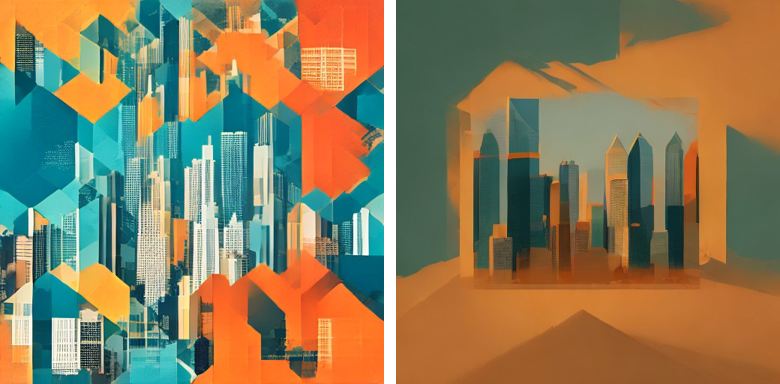

seed 102: левое | правое


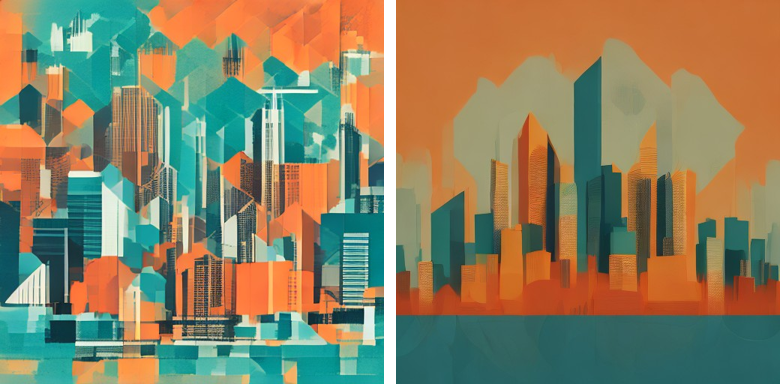

seed 103: левое | правое


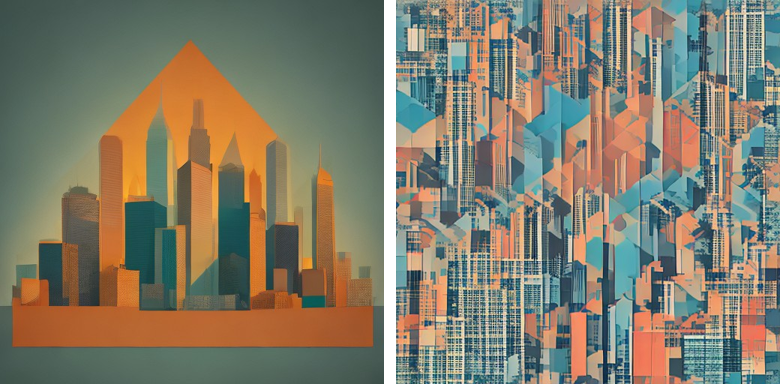

seed 104: левое | правое


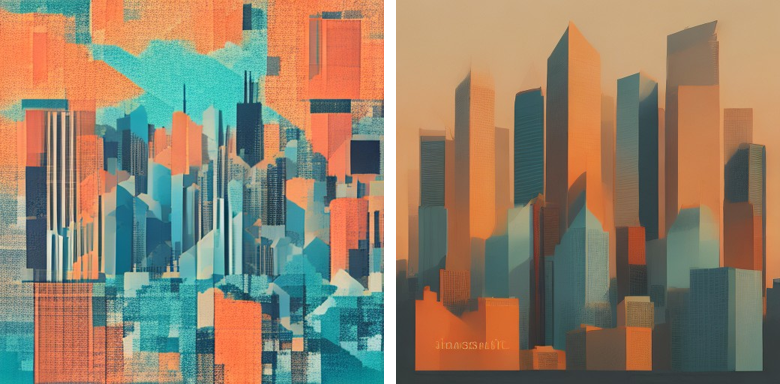

seed 105: левое | правое


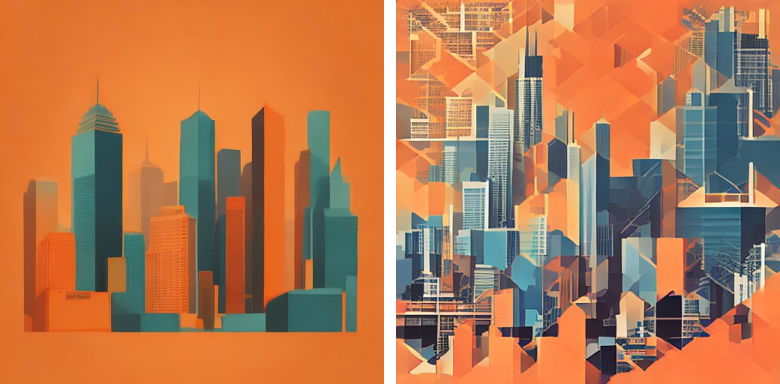

In [11]:
blind_dir = artifacts / "v07"
_written = L.blind_sheets(VARIANT, str(blind_dir))   # возвращаемый ключ не показываем
del _written
for sd in SEEDS:
    print(f"seed {sd}: левое | правое")
    display(Image.open(blind_dir / f"blind_{sd}.png"))

In [14]:
# Слепая оценка — заполнить ДО открытия ключа: choice = "left" или "right", reason — одно предложение.
BLIND_EVALUATOR = "автор работы"            # кто оценивал
BLIND_CHOICE_RECORDED_AT = "12.11.2026 12:57"   # "дд.мм.гггг чч:мм" — до открытия ключа
BLIND_CHOICES = {
    101: {"choice": "left", "reason": "Слева абстрактные геометрические плоскости в бирюзовом и оранжевом, хоть и перегруженные; справа размытый живописный горизонт в рамке без плоского геометрического стиля."},
    102: {"choice": "right", "reason": "Справа читаемый слоистый горизонт из прямоугольных башен в бирюзово-оранжевой палитре и спокойная композиция; слева плотный коллаж, в котором горизонт теряется."},
    103: {"choice": "left", "reason": "Слева минималистичный слоистый горизонт из башен на фоне оранжевого треугольника в плоском стиле; справа плотная мозаика без читаемого горизонта."},
    104: {"choice": "left", "reason": "Пограничный случай: справа чистый слоистый горизонт, но внизу буквоподобная надпись, запрещённая брифом; слева без текста, плоские бирюзово-оранжевые формы, хотя перегружено."},
    105: {"choice": "left", "reason": "Слева минималистичный горизонт бирюзовых и оранжевых башен на оранжевом фоне; справа плотная мозаика, далёкая от минимализма."},
}
blind_done = bool(BLIND_EVALUATOR and BLIND_CHOICE_RECORDED_AT) and all(
    v["choice"] in ("left", "right") and v["reason"].strip() for v in BLIND_CHOICES.values())
print("слепая оценка записана" if blind_done else "PENDING: заполните BLIND_CHOICES, BLIND_EVALUATOR и BLIND_CHOICE_RECORDED_AT")

слепая оценка записана


In [15]:
# Ключ открывается только после записанного выбора. Победы модели B и двусторонняя вероятность исхода при равенстве моделей.
if not blind_done:
    raise RuntimeError("PENDING: слепая оценка не записана — ключ не открывается. Заполните ячейку выше и выполните ячейки с неё.")
blind_key = json.loads((blind_dir / "blind_key.json").read_text(encoding="utf-8"))
blind_rows = []
for sd in SEEDS:
    left = blind_key[str(sd)]
    right = B_KEY if left == A_KEY else A_KEY
    chosen = left if BLIND_CHOICES[sd]["choice"] == "left" else right
    blind_rows.append({"seed": sd, "left": left, "right": right, "choice": BLIND_CHOICES[sd]["choice"], "chosen_model": chosen, "reason": BLIND_CHOICES[sd]["reason"]})
wins_b = sum(r["chosen_model"] == B_KEY for r in blind_rows)
n_pairs = len(blind_rows)
tail = sum(math.comb(n_pairs, i) for i in range(max(wins_b, n_pairs - wins_b), n_pairs + 1)) / 2 ** n_pairs
p_two_sided = min(1.0, 2 * tail)
blind_result = {"evaluator": BLIND_EVALUATOR, "recorded_at": BLIND_CHOICE_RECORDED_AT, "criterion": "better matches the brief",
                "rows": blind_rows, "wins_B": wins_b, "wins_A": n_pairs - wins_b, "p_two_sided_equal_models": p_two_sided,
                "reject_equality_at_0.05": p_two_sided < 0.05}
(artifacts / "blind_result.json").write_text(json.dumps(blind_result, ensure_ascii=False, indent=2), encoding="utf-8")
display(pd.DataFrame(blind_rows).set_index("seed"))
print(f"{B_KEY} (B) выбран в {wins_b} парах из {n_pairs}, {A_KEY} (A) — в {n_pairs - wins_b}; двусторонняя вероятность при равенстве моделей {p_two_sided:.4f}"
      f" — {'меньше' if p_two_sided < 0.05 else 'не меньше'} 0,05")

,left,right,choice,chosen_model,reason
seed,,,,,
101,turbo,lcm,left,turbo,Слева абстрактные геометрические плоскости в б...
102,turbo,lcm,right,lcm,Справа читаемый слоистый горизонт из прямоугол...
103,lcm,turbo,left,lcm,Слева минималистичный слоистый горизонт из баш...
104,turbo,lcm,left,turbo,Пограничный случай: справа чистый слоистый гор...
105,lcm,turbo,left,lcm,Слева минималистичный горизонт бирюзовых и ора...


lcm (B) выбран в 3 парах из 5, turbo (A) — в 2; двусторонняя вероятность при равенстве моделей 1.0000 — не меньше 0,05


## Изображения с подписями моделей

Показываются только после слепой оценки.

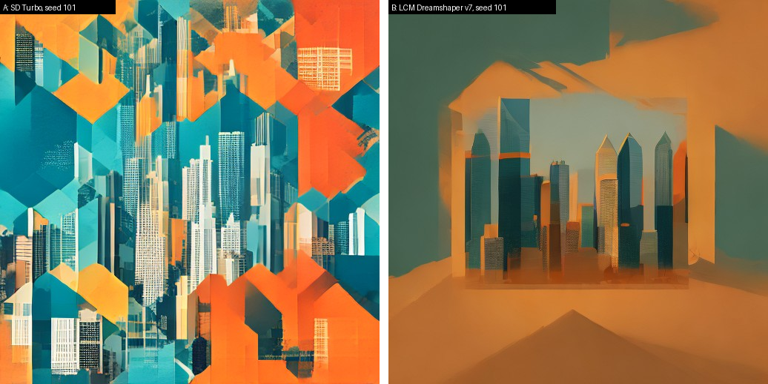

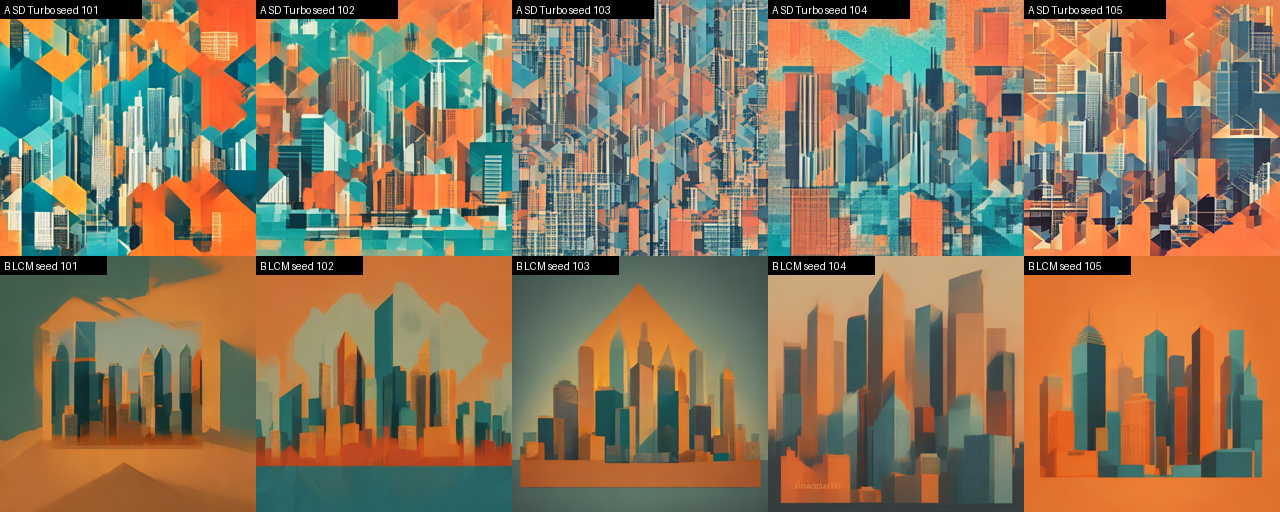

Ошибка 2: верхний ряд — LCM 4 шага (вариант), нижний — LCM 1 шаг


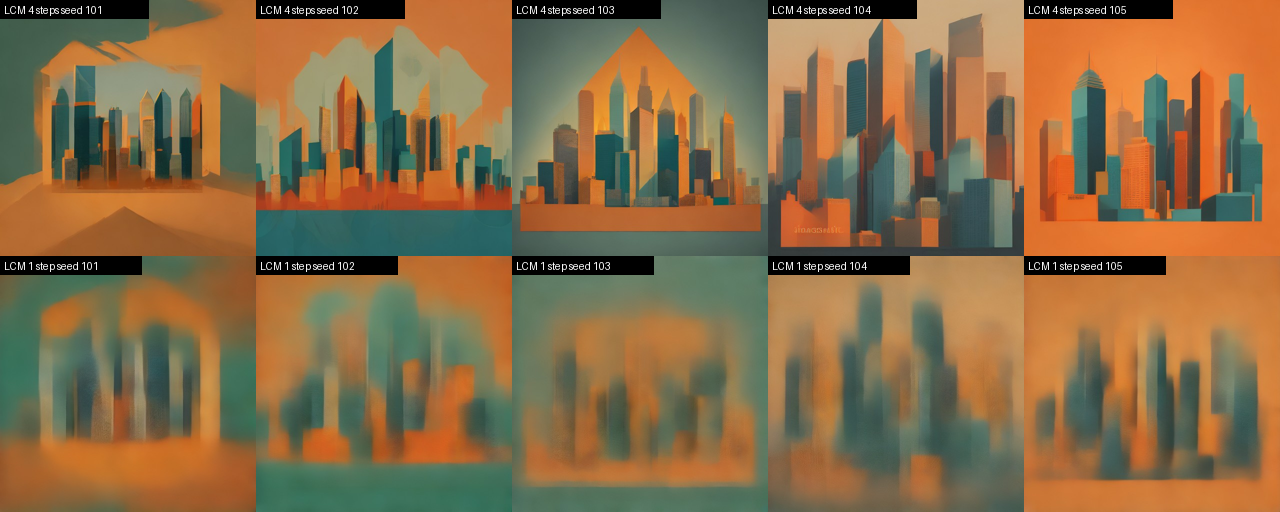

Демо-вариант 1 (бриф 1)


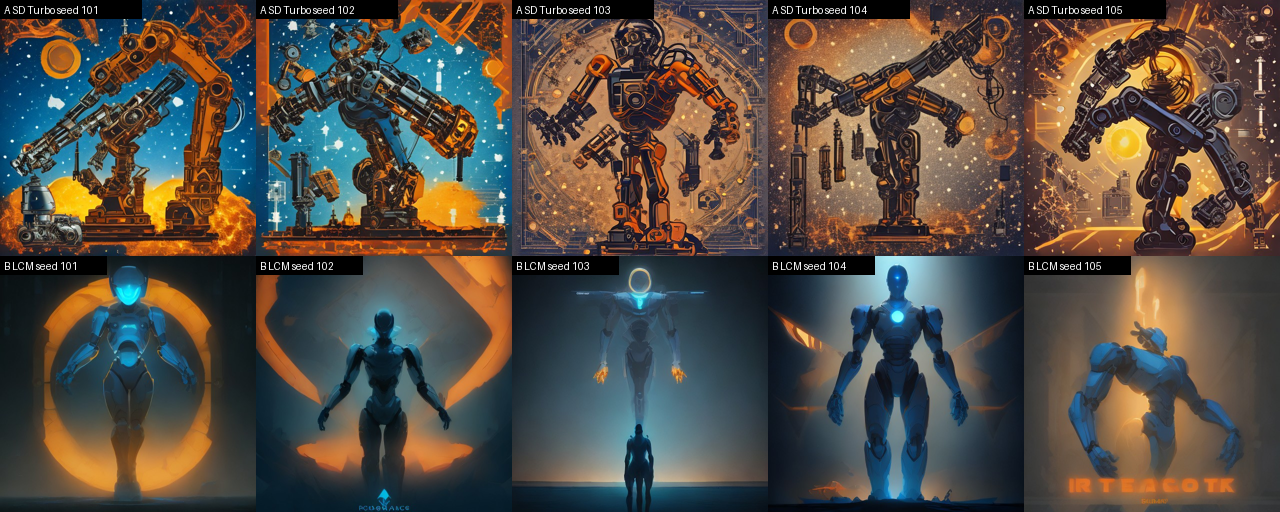

In [16]:
def labeled(img, text, size):
    img = img.convert("RGB").resize((size, size))
    draw = ImageDraw.Draw(img)
    draw.rectangle([0, 0, 8 + 7 * len(text), 18], fill="black")
    draw.text((4, 4), text, fill="white")
    return img

def grid(rows_spec, size=256):
    # rows_spec: [(folder, model, label)] — строка на модель, столбец на seed
    sheet = Image.new("RGB", (size * len(SEEDS), size * len(rows_spec)), "white")
    for i, (folder, model, label) in enumerate(rows_spec):
        for j, sd in enumerate(SEEDS):
            sheet.paste(labeled(Image.open(pathlib.Path(folder) / f"{model}_s{sd}.jpg"), f"{label} seed {sd}", size), (j * size, i * size))
    return sheet

v07 = artifacts / "v07"
comparison = Image.new("RGB", (512 * 2 + 12, 512), "white")
comparison.paste(labeled(Image.open(v07 / "turbo_s101.jpg"), "A: SD Turbo, seed 101", 512), (0, 0))
comparison.paste(labeled(Image.open(v07 / "lcm_s101.jpg"), "B: LCM Dreamshaper v7, seed 101", 512), (512 + 12, 0))
comparison.save(artifacts / "comparison_seed101.png")
all_seeds = grid([(v07, "turbo", "A SD Turbo"), (v07, "lcm", "B LCM")])
all_seeds.save(artifacts / "comparison_all_seeds.png")
err_sheet = grid([(v07, "lcm", "LCM 4 steps"), (artifacts / "v07_err", "lcm", "LCM 1 step")])
err_sheet.save(artifacts / "error_lcm_1step.png")
demo_sheet = grid([(artifacts / "demo" / "v01", "turbo", "A SD Turbo"), (artifacts / "demo" / "v01", "lcm", "B LCM")])
demo_sheet.save(artifacts / "demo" / "comparison_variant01.png")
display(comparison.resize((768, 384)))
display(all_seeds)
print("Ошибка 2: верхний ряд — LCM 4 шага (вариант), нижний — LCM 1 шаг")
display(err_sheet)
print("Демо-вариант 1 (бриф 1)")
display(demo_sheet)

In [21]:
# Описание глазами (шаги 6 плана и проверка варианта) — заполнить после просмотра листов с подписями.
# bands: читаются ли слои горизонта как отдельные геометрические полосы бирюзового и оранжевого (True/False).
VISUAL_CHECK = {
    "bands": {"turbo": {101: False, 102: False, 103: False, 104: False, 105: False},
              "lcm": {101: False, 102: True, 103: True, 104: True, 105: True}},
    "seed101": ("A (SD Turbo): плотная мозаика из бирюзовых и оранжевых шестиугольных и угловатых плоскостей с вкраплениями почти фотографических небоскрёбов; "
                "цвета брифа есть, но единого горизонта и минимализма нет. B (LCM): мягкий, размытый горизонт бирюзовых башен в прямоугольной рамке на оранжевом фоне "
                "с треугольным холмом; палитра совпадает, композиция центрирована, но края смазаны и плоского геометрического стиля нет. "
                "Буквоподобных знаков и людей на обоих нет."),
    "defects": ("SD Turbo на всех пяти seed — перегруженная мозаика без читаемого горизонта; букв и людей нет. LCM на seed 102–105 — слоистый горизонт башен "
                "в бирюзово-оранжевой палитре, на seed 101 — размытый горизонт в рамке; на LCM seed 104 внизу слева буквоподобная надпись (текст запрещён брифом). "
                "Узнаваемых зданий и людей нет ни у одной модели; изображения синтетические и не выдаются за фотографию города."),
    "lcm_1step": ("LCM с одним шагом на всех пяти seed даёт размытые пятна: башни «плавают» и растворяются в бирюзово-оранжевом тумане, границ нет — "
                  "как в разделе 6.4 методички; это следствие изменения конфигурации, а не свойство модели."),
}
visual_done = all(v is not None for m in VISUAL_CHECK["bands"].values() for v in m.values()) and all(
    VISUAL_CHECK[key].strip() for key in ("seed101", "defects", "lcm_1step"))
if visual_done:
    bands_count = {m: sum(VISUAL_CHECK["bands"][m].values()) for m in (A_KEY, B_KEY)}
    print("полосы горизонта читаются:", bands_count)
else:
    print("PENDING: заполните VISUAL_CHECK после просмотра листов")

полосы горизонта читаются: {'turbo': 0, 'lcm': 4}


In [22]:
# Время (шаг 8 плана): время на изображение A и B в одном запуске и их отношение.
rows_v07 = {r["metric"]: r for r in run_v07["rows"]}
timing = {"A_seconds_per_image": rows_v07["seconds"]["A"], "A_seconds_s": rows_v07["seconds"]["s"], "B_seconds_per_image": rows_v07["seconds"]["B"],
          "ratio_B_over_A": rows_v07["seconds"]["B"] / rows_v07["seconds"]["A"], "threads": torch.get_num_threads(),
          "loads": run_v07["loads"], "note": "one run in one Colab CPU session; not comparable with Engee seconds"}
print(f"SD Turbo {timing['A_seconds_per_image']:.1f} с, LCM {timing['B_seconds_per_image']:.1f} с на изображение; отношение {timing['ratio_B_over_A']:.2f}; потоков {timing['threads']}")

SD Turbo 81.7 с, LCM 129.7 с на изображение; отношение 1.59; потоков 1


In [23]:
# Проверка гипотез H1–H6 и паспорт эксперимента. Все измеряемые поля — из этого сеанса.
cls = {x["metric"]: x for x in classification}
hyp = {
    "H1": {"text": "LCM clip_brief higher than SD Turbo by more than 2s and more than 1.0",
           "confirmed": bool(rows_v07["clip_brief"]["d"] > 0 and rows_v07["clip_brief"]["sig_2s"] and cls["clip_brief"]["over_tolerance"])},
    "H2": {"text": "time ratio LCM / SD Turbo at least 1.5", "confirmed": bool(timing["ratio_B_over_A"] >= 1.5)},
    "H3": {"text": "clip_text differs by no more than 1.0", "confirmed": bool(abs(rows_v07["clip_text"]["d"]) <= 1.0)},
    "H4": {"text": "edge and contrast differ by no more than 10 % of A", "confirmed": bool(not cls["edge"]["over_tolerance"] and not cls["contrast"]["over_tolerance"])},
    "H5": {"text": "LCM chosen in at least 3 of 5 blind pairs", "confirmed": bool(blind_result["wins_B"] >= 3)},
    "H6": {"text": "horizon layers read as teal and orange bands on at least 3 of 5 seeds for each model",
           "confirmed": bool(visual_done and min(bands_count.values()) >= 3) if visual_done else None},
}
complete = blind_done and visual_done
intentional_errors = {"error_1_one_seed": one_seed_error, "error_2_lcm_1_step": step_error, "error_3_time_from_different_runs": time_error}
(artifacts / "intentional_errors.json").write_text(json.dumps(intentional_errors, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
passport = {
    "status": "COMPLETE" if complete else "PARTIAL",
    "date_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "variant": VARIANT, "brief_no": BRIEF_NO, "pair_no": PAIR_NO, "brief": BRIEF,
    "hypothesis_recorded_at": HYPOTHESIS_RECORDED_AT, "hypotheses": hyp, "tolerance": TOLERANCE, "significance": "abs(d) > 2 * s_A, s over 5 seeds of model A",
    "models": {m: {**{p: L.MODELS[m][p] for p in ("repo", "revision", "steps", "guidance", "size", "note")}, "scheduler": "from the repository (not replaced)",
                   "license": LICENSES[m]} for m in (A_KEY, B_KEY)},
    "clip": {"repo": L.CLIP_ID, "revision": L.CLIP_REVISION, "text_probe": L.TEXT_PROBE, "license": LICENSES["clip"]},
    "seeds": SEEDS, "dtype": "float32", "device": "cpu", "generator": "torch.Generator('cpu')", "threads": torch.get_num_threads(),
    "environment": environment,
    "runs": {name: {"call": call, "total_seconds": r["total_seconds"], "loads": r["loads"], "peak_rss_gb": r["peak_rss_gb"]} for name, call, r in (
        ("v07", 'L.variant_summary(7, save_dir="v07")', run_v07),
        ("v07_err", 'L.variant_summary(7, save_dir="v07_err", cfg={"lcm": {"steps": 1}})', run_err),
        ("v01", 'L.variant_summary(1, save_dir="v01")', run_demo))},
    "blind": {"evaluator": BLIND_EVALUATOR, "recorded_at": BLIND_CHOICE_RECORDED_AT, "wins_B": blind_result["wins_B"], "p_two_sided": blind_result["p_two_sided_equal_models"]},
    "visual_check": VISUAL_CHECK if visual_done else None,
    "timing": timing,
    "demo_all_within_2s": demo_check["all_within_2s"],
}
(artifacts / "passport.json").write_text(json.dumps(passport, ensure_ascii=False, indent=2, allow_nan=False, default=str), encoding="utf-8")
env_lines = ["STATUS=ACTUAL", f"execution_environment={environment['execution_environment']}", "device=cpu", f"cuda_available={environment['cuda_available']}",
             f"cpu_count={environment['cpu_count']}", f"torch_threads={environment['torch_threads']}", f"ram_gb={environment['ram_gb']}", f"python={environment['python']}",
             *[f"{name}={v}" for name, v in environment["packages"].items()], f"platform={environment['platform']}",
             *[f"environment_fix={x}" for x in ENVIRONMENT_FIXES],
             *[f"model_{m}={L.MODELS[m]['repo']}@{L.MODELS[m]['revision']}" for m in (A_KEY, B_KEY)], f"clip={L.CLIP_ID}@{L.CLIP_REVISION}",
             f"lab10_lib.py_sha256={EXPECTED_SHA256['lab10_lib.py']}", f"started_at_utc={environment['started_at_utc']}"]
(reports / "environment.txt").write_text("\n".join(env_lines) + "\n", encoding="utf-8")
print(json.dumps({"status": passport["status"], "hypotheses": {h: v["confirmed"] for h, v in hyp.items()}}, ensure_ascii=False))

{"status": "COMPLETE", "hypotheses": {"H1": false, "H2": true, "H3": true, "H4": false, "H5": true, "H6": false}}


In [24]:
# Итоговая проверка файлов и чек-листа методички.
required = [artifacts / "metrics.json", artifacts / "per_seed_metrics.csv", artifacts / "classification.json", artifacts / "blind_result.json",
            artifacts / "intentional_errors.json", artifacts / "passport.json", artifacts / "comparison_seed101.png", artifacts / "comparison_all_seeds.png",
            artifacts / "error_lcm_1step.png", artifacts / "error_lcm_1step" / "metrics_lcm_1step.json", artifacts / "demo" / "demo_check.json",
            artifacts / "demo" / "comparison_variant01.png", artifacts / "v07" / "blind_key.json", reports / "environment.txt",
            *[artifacts / "v07" / f"{m}_s{sd}.jpg" for m in (A_KEY, B_KEY) for sd in SEEDS], *[artifacts / "v07" / f"blind_{sd}.png" for sd in SEEDS]]
for path in required:
    assert path.is_file() and path.stat().st_size > 0, f"нет файла: {path}"
    if path.suffix == ".json":
        json.loads(path.read_text(encoding="utf-8"))
from datetime import timedelta
hypothesis_utc = datetime.strptime(HYPOTHESIS_RECORDED_AT, "%d.%m.%Y %H:%M").replace(tzinfo=timezone(timedelta(hours=3)))   # время записи — МСК
TABLE_2_2 = {"turbo": (1, 0.0, 512), "lcm": (4, 8.0, 512)}
checklist = {
    "hypothesis dated before run": hypothesis_utc < datetime.fromisoformat(environment["started_at_utc"]),
    "model configurations as in table 2.2": run_v07["cfg"] is None and all(
        (L.MODELS[m]["steps"], L.MODELS[m]["guidance"], L.MODELS[m]["size"]) == v for m, v in TABLE_2_2.items()),
    "all five seeds": sorted(run_v07["per_seed"].seed.unique().tolist()) == SEEDS,
    "blind choice before key": blind_done,
    "images described": visual_done,
    "licenses stated": all(LICENSES.values()),
}
assert all(checklist.values()), checklist
print("все файлы на месте; чек-лист:", checklist)

все файлы на месте; чек-лист: {'hypothesis dated before run': True, 'model configurations as in table 2.2': True, 'all five seeds': True, 'blind choice before key': True, 'images described': True, 'licenses stated': True}


In [25]:
# Архив результатов для переноса в репозиторий: artifacts/, reports/ и записанная библиотека.
import zipfile
with zipfile.ZipFile("lab10_results.zip", "w", zipfile.ZIP_DEFLATED) as archive:
    for path in sorted([*artifacts.rglob("*"), *reports.rglob("*")]):
        if path.is_file():
            archive.write(path)
    for name in EXPECTED_SHA256:
        archive.write(name)
print("lab10_results.zip:", round(pathlib.Path("lab10_results.zip").stat().st_size / 1024), "KiB")
try:
    from google.colab import files
    files.download("lab10_results.zip")
except ImportError:
    pass

lab10_results.zip: 7087 KiB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>